# Connectome Spectrum Transform from tractography
We generate a high resolution connectome from tractography data. The method associates the endpoints of streamlines to closest sources. Because the sources are in close proximity (~2mm), associating the endpoints to exactly one source is a point of error. Therefore, following [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)'s methodology, we smooth the connectivity to disperse the endpoint of streamlines across vertices in the proximity of the endpoint. 

## 📦 Imports

In [3]:
import mindmap as mm
import scipy as sp
import numpy as np
import pygsp
import nibabel as nib
import pyvista as pv

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `parc`: Parcellation 
- `ctx`: Cortical mask
- `t12diff`: Transformation (T1 -> diffusion)
- `tracto`: Tractography
- `cras`: Translation (T1 -> RAS)
- `src`: Source space (after forward solution)

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: subject id

In [ ]:
############## Parameters ##############
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
########################################

reader = mm.io.dataset_reader(fconfig)

data = reader(sub, "src", "cras", "tracto", "t12diff", "parc", "ctx")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- tracto
- parc
- t12diff
- src
- cras
- ctx
Missing objects:


## Create Structural Connectome from Tractography

#### ⚙️ **<font color=green>Align sources and streamlines </font>**
To align the sources with the streamline endpoints, we scale the sources to [mm] and apply the CRAS translation. Next, we also apply the inverse diffusion affine transform, as the diffusion space is slightly different from the T1 space.

In [15]:
# sources 
pos = mm.utils.get_src_position(data["src"])
pos = pos*1000 + data["cras"] - data["t12diff"][:3,3]  # in [mm]

# source geodesic distances
geodist = mm.utils.get_geodist(data["src"])*1000 # in [mm]

# streamline endpoints
voxel_size = data["tracto"].header["voxel_sizes"].reshape(1,-1)
starts     = np.array([stream[0] for stream in data["tracto"].streamlines]) / voxel_size
ends       = np.array([stream[-1] for stream in data["tracto"].streamlines]) / voxel_size

#### ⚙️ **<font color=green>Delete streamlines having endpoints outside of cortical regions</font>**:
 Sources are only in the cortex, so we consider only cortical-cortical streamlines.

In [16]:
inv_affine = np.linalg.inv(data["ctx"].affine)
volume     = data["ctx"].get_fdata()

retain = []
for points in [starts, ends]:
    vox  = nib.affines.apply_affine(inv_affine, points)                 # transfer points to T1 voxel ids
    vox  = np.round(vox).astype(int)                                   
    mask = volume[vox[:,0], vox[:,1], vox[:,2]].astype(bool)            # retrieve ctx mask value at voxel postion

    retain.append(mask)
    
retain = retain[0] * retain[1]        # retain is True if start and end point are in the cortical area.
print(f"Quantity of streamlines removed: {np.sum(~retain)/len(retain)*100:.3}%")

dismiss_s = starts[~retain] # for plotting
dismiss_e = ends[~retain]

starts = starts[retain]
ends   = ends[retain]

Quantity of streamlines removed: 30.4%


🌟 **Visualize alignment**

In [17]:
# points
src       = pv.PolyData(nib.affines.apply_affine(inv_affine, pos))
retained  = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([starts, ends])))
dismissed = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([dismiss_s, dismiss_e])))

# mask
ctx_mask = pv.ImageData(dimensions=data["ctx"].shape, spacing=(1,1,1), origin=(0,0,0))
ctx_mask.point_data["scalars"] = data["ctx"].get_fdata().flatten(order="F")

p = pv.Plotter()
p.add_mesh(src, color="black", render_points_as_spheres=True, point_size=8, label="sources")
p.add_mesh(retained, color="green", label="streamline endpoints")
p.add_mesh(ctx_mask.contour(3), color="white", opacity=0.2)
p.add_legend()
p.show()

Widget(value='<iframe src="http://localhost:46155/index.html?ui=P_0x7f6d8ef22c50_1&reconnect=auto" class="pyvi…

🌟 **Visualize region-based connectome** <br>
We start by visualizing the region-based connectome to check the quality of the tractogram. The regions with 0 degree are sub-cortical regions that we omitted previously.

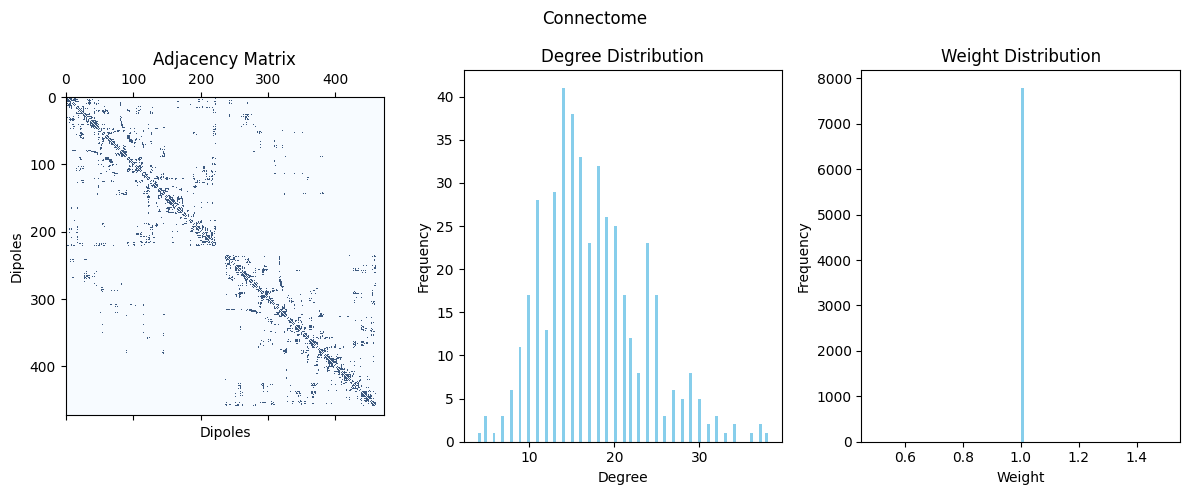

In [19]:
start_lab = data["parc"].label_points(starts, id=True)
end_lab   = data["parc"].label_points(ends, id=True)

dismiss   = (start_lab==0) | (end_lab==0)
start_lab = start_lab[~dismiss]
end_lab   = end_lab[~dismiss]

n = data["parc"].n_regions

conn = np.zeros(shape=(n,n))
for i,j in zip(start_lab-1, end_lab-1):
    conn[i, j] += 1

conn = conn + conn.T
np.fill_diagonal(conn, 0)

mm.viz.plot_connectome(conn>0, nonzero=True)

#### ⚙️ **<font color=green>Build connectivity from closest sources</font>**
Use a closest neighborhood algorithm to associate each streamline endpoint to its closest dipole.

In [9]:
# find closest source to streamlines endpoints
kd_tree = sp.spatial.cKDTree(pos)
_, start_idx = kd_tree.query(starts)
_, end_idx     = kd_tree.query(ends)

# create sc matrix
n  = data["src"][0]["nuse"] + data["src"][1]["nuse"]
sc = np.zeros((n, n))

for i,j in zip(start_idx, end_idx):
    sc[i, j] += 1

sc = (sc + sc.T)
#sc[sc<50] = 0
sc[sc>0] = 1
np.fill_diagonal(sc, 0)

🌟 **Visualize dipole-based connectome**

Number of isolated dipoles: 105


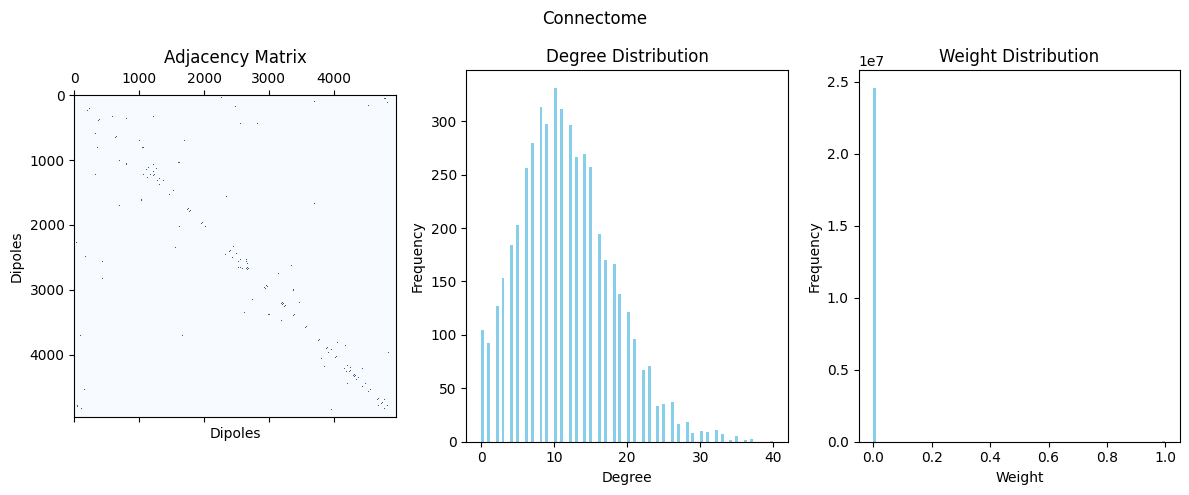

In [10]:
# sort by parcellation labels
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)
viz    = sc[idx][:,idx]

# compute number of isolated dipoles
stream_per_dipole = viz.sum(axis=1)
print(f"Number of isolated dipoles: {np.sum(stream_per_dipole==0)}")

# plot
mm.viz.plot_connectome(viz, name="Connectome")

#### ⚙️ **<font color=green>Smooth connectivity according to Sina Mansour et. al (2020)</font>**
The endpoints of streamlines are usually connected to multiple neurons. If the spacing between dipoles is very small, than the streamlines are most likely originating/terminating in multiple dipoles. To incorporate this in our connectomes, we can smooth the endpoints of streamlines with a gaussian kernel of approximately 2 mm. (methodology described in [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)) <br><br>
🚨 Only recommended if dipole spacing is smaller than 2 mm

🎚️ **<font color=pink>Smoothing</font>**:
- `fwhm`:Full width half maximum (gaussian property for smoothing connectivity)
- `epsilon`: Influences smoothing radius
- `dim`: Smoothing dimensionality (surface is 2d)

In [11]:
############### Parameters ###############
# Smoothing
fwhm      = 12      
epsilon   = 1e-07     
dim       = 2           
##########################################

# compute gaussian coefficients
sigma    = fwhm / np.sqrt(8*np.log(2))                                      # gaussian std 
max_dist = sigma * (-sp.stats.norm.ppf((1 - (1-epsilon)**(1/dim)) / 2))

geodist[geodist > 10] = 0
geodist.eliminate_zeros()


gaussian = -(geodist**2/(2*sigma**2))
np.exp(gaussian.data, out=gaussian.data)
gaussian += sp.sparse.eye(gaussian.shape[0], dtype=gaussian.dtype, format="csr")
gaussian /= sp.sparse.linalg.norm(gaussian, ord=1, axis=1)[:,None]

# define incidence matrices
indices = np.argwhere(sc>0)
n, s    = data["src"][0]["nuse"]+data["src"][1]["nuse"], len(indices)
M1, M2  = np.zeros((n,s)), np.zeros((n,s))

for i, j in enumerate(indices):
    M1[j[0], i] = 1
    M2[j[1], i] = 1

# smooth incidence
M1s = (gaussian.T @ M1)
M2s = (gaussian.T @ M2)

# compute structural connectome
sc = (M1s @ M2s.T) + (M2s @ M1s.T)
sc = (sc + sc.T)/2
sc[sc>0] = 1
np.fill_diagonal(sc, 0)

🌟 **Visualize smoothed connectivity**

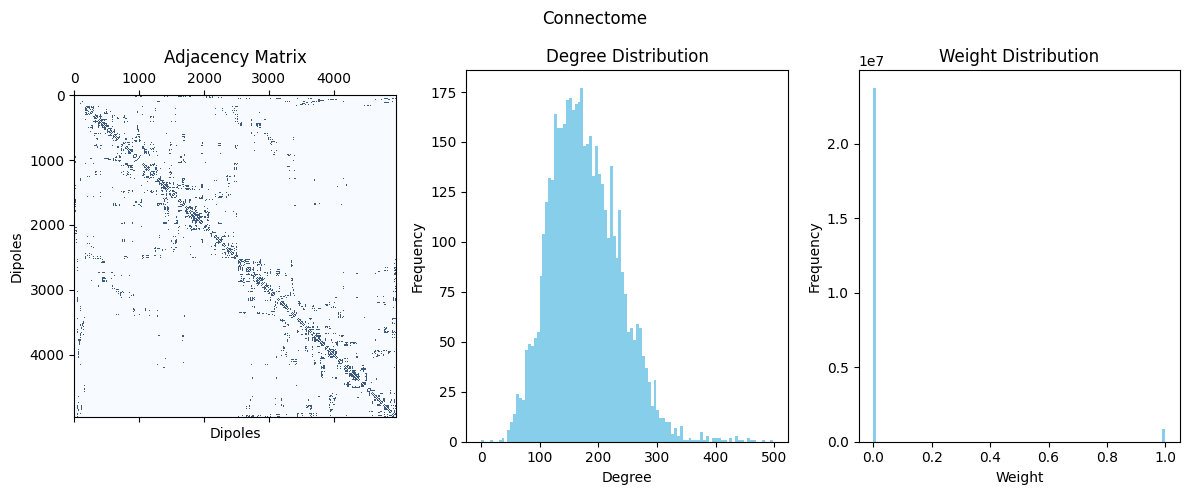

In [12]:
# sort by parcellation labels
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)
viz    = sc[idx][:,idx]

mm.viz.plot_connectome(viz, name="Connectome")

#### ⚙️ **<font color=green>Add neighboring connections</font>**
Tractography reveals the pathways within the white matter, but it is also understood that neurons communicate with their neighbors through the gray matter. To simulate this interaction, we artificially introduce connections between neighboring dipoles. Distance to measure closest neighbors is the geodesic distance on the surface.

🎚️ **<font color=pink>Geometry</font>**:
- `dmax`: Maximum distance in [mm] at which to connect a neighbor.

In [13]:
geom = mm.utils.build_geometry(data["src"], dmax=10)
sc   = (sc>0) | geom

TypeError: ufunc 'bitwise_or' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

🌟 **Visualize closed connectivity**

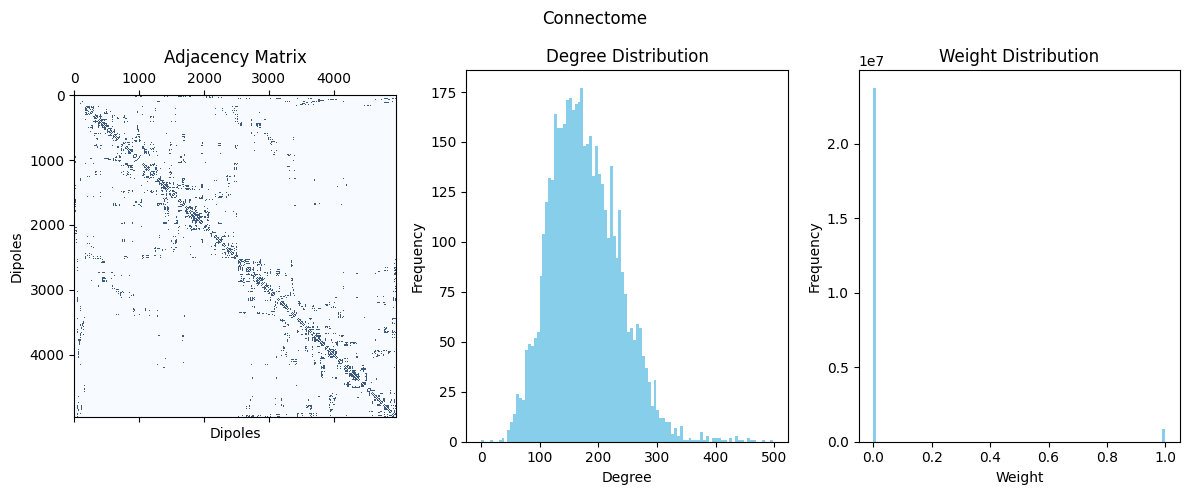

In [14]:
# sort by parcellation labels
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)
viz    = sc[idx][:,idx]

mm.viz.plot_connectome(viz, name="Connectome")

## Connectome Spectrum Transform

#### ⚙️ <font color=green>**Compute the Connectome Spectrum Transform (CST)**</font>
The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eigenvectors) of this transform are characteristic of the connectome. Visualize them to assess the quality of the CST.

In [13]:
coords = mm.utils.get_src_position(data["src"])

G = pygsp.graphs.Graph(sc, lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/pygsp/graphs/graph.py:496: RuntimeWarning: divide by zero encountered in power
  d = np.power(self.dw, -0.5)
2025-06-17 08:38:22,511:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


🌟 **Visualize harmonics**

In [14]:
mm.viz.plot_harmonics(data["src"], cst).show()

Widget(value='<iframe src="http://localhost:40781/index.html?ui=P_0x7cbddf0c7250_1&reconnect=auto" class="pyvi…

#### 💾 Save the SC

In [15]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography for subject: {sub}")
np.save(folder/f"{sub}_sc-tracto.npy", sc)

Saving SC from tractography for subject: vepcon_sub-10


#### 💾 Save the CST

In [16]:
folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from tractography for subject: {sub}")
np.save(folder/f"{sub}_cst.npy", cst)

Saving CST from tractography for subject: vepcon_sub-10
